# XGBoost for loan default

Train gradient-boosted trees (XGBoost) on the shared partitions from [03_feature_engineering.ipynb](03_feature_engineering.ipynb). Hyperparameters and the classification threshold are chosen with cross-validation on the training set only; the test set is used once for the final scores. The metric columns match [04b_model_logistic_regression.ipynb](04b_model_logistic_regression.ipynb) so the results can be stacked in 05_evaluation.

## 1. Load the shared training and test data

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    accuracy_score, auc, brier_score_loss, confusion_matrix, f1_score,
    log_loss, precision_recall_curve, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict
from xgboost import XGBClassifier

In [2]:
ROOT = next(
    (folder for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / 'data' / 'financial_loan_dataset_v2.csv').is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError('Open the notebook from the project folder or its notebooks directory.')
DATA_DIR = ROOT / 'data'
RESULTS_DIR = ROOT / 'results'
TARGET = 'loan_default'
SEED = 42

split_paths = [DATA_DIR / filename for filename in ('train.csv', 'test.csv')]
if not all(path.is_file() for path in split_paths):
    raise FileNotFoundError('Run 03_feature_engineering.ipynb to generate train.csv and test.csv.')

train_df, test_df = (pd.read_csv(path) for path in split_paths)
y_train, y_test = train_df[TARGET], test_df[TARGET]
print(f'Train: {len(y_train):,} rows | Test: {len(y_test):,} rows')
print(f'Default rate: train {y_train.mean():.1%} | test {y_test.mean():.1%}')

Train: 960 rows | Test: 240 rows
Default rate: train 20.6% | test 20.8%


## 2. Define the feature sets

- Uses the `gradient_boosting` set recommended in notebook 03: raw financials, engineered ratios, delinquency and credit features, and the two Qwen3.5 non-thinking text scores.
- Trees split on thresholds, so no scaling or log transforms are needed, and overlapping ratios do not distort the model the way they distort logistic regression coefficients.
- The tabular-only set drops the two Qwen scores to measure what the text features add.

In [3]:
qwen_cols = ['slm_sentiment_score', 'slm_strain_score']
tabular_cols = [
    'age', 'annual_income', 'credit_score', 'credit_score_tier', 'loan_amount',
    'debt_to_income_ratio', 'late_payments_12m', 'account_tenure_months',
    'loan_to_income_ratio', 'total_burden_ratio', 'residual_monthly_income',
    'late_payment_intensity', 'credit_utilization_stress', 'risk_adjusted_leverage',
    'employment_stability_score',
]
xgb_cols = tabular_cols + qwen_cols
print(f'{len(xgb_cols)} predictors ({len(tabular_cols)} tabular + {len(qwen_cols)} Qwen)')

17 predictors (15 tabular + 2 Qwen)


## 3. Tune hyperparameters with cross-validation

XGBoost builds shallow trees one after another, and each new tree corrects the errors of the trees before it. The grid below controls how complex each tree is (`max_depth`, `min_child_weight`), how much each tree contributes (`learning_rate`), and how many trees are added (`n_estimators`). Row and column subsampling (0.8) add randomness that reduces overfitting.

- Grid search scores each combination by ROC AUC on 5-fold stratified cross-validation of the training set.
- The threshold maximises macro F1 on out-of-fold training predictions, the same rule as in 04b. About 21% of borrowers default, so the default 0.50 cut-off misses many of them.

In [4]:
fixed_params = dict(
    subsample=0.8, colsample_bytree=0.8, eval_metric='logloss',
    random_state=SEED, n_jobs=1,
)
param_grid = {
    'max_depth': [1, 2, 3],
    'learning_rate': [0.01, 0.03, 0.1],
    'n_estimators': [100, 300, 600],
    'min_child_weight': [5, 10, 20],
}
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
search = GridSearchCV(
    XGBClassifier(**fixed_params), param_grid, scoring='roc_auc', cv=folds, n_jobs=-1,
).fit(train_df[xgb_cols], y_train)
best_params = search.best_params_
print('Best parameters:', best_params)
print(f'Cross-validated ROC AUC: {search.best_score_:.4f}')

oof_probabilities = cross_val_predict(
    XGBClassifier(**fixed_params, **best_params), train_df[xgb_cols], y_train,
    cv=folds, method='predict_proba',
)[:, 1]
thresholds = np.arange(5, 96) / 100
oof_scores = [f1_score(y_train, oof_probabilities >= t, average='macro') for t in thresholds]
tuned_threshold = thresholds[int(np.argmax(oof_scores))]
print(f'Training-selected threshold: {tuned_threshold:.2f} (out-of-fold macro F1 {max(oof_scores):.4f})')

Best parameters: {'learning_rate': 0.01, 'max_depth': 1, 'min_child_weight': 10, 'n_estimators': 600}
Cross-validated ROC AUC: 0.8282


Training-selected threshold: 0.36 (out-of-fold macro F1 0.7190)


## 4. Evaluate on the held-out test set

Rows compare default parameters, the tuned model with and without the Qwen scores (same hyperparameters), and the tuned model at the training-selected threshold. Accuracy, F1 and the confusion-matrix counts depend on the threshold; ROC AUC, PR AUC, Brier score and log loss use the predicted probabilities.

In [5]:
def evaluate_predictions(name, y_true, probabilities, threshold=0.50):
    predicted = probabilities >= threshold
    tn, fp, fn, tp = confusion_matrix(y_true, predicted, labels=[0, 1]).ravel()
    precision, recall, _ = precision_recall_curve(y_true, probabilities)
    return {
        'Model': name,
        'Threshold': threshold,
        'Accuracy': accuracy_score(y_true, predicted),
        'Precision': precision_score(y_true, predicted, zero_division=0),
        'Recall': recall_score(y_true, predicted),
        'Specificity': tn / (tn + fp),
        'F1_Score': f1_score(y_true, predicted),
        'Macro_F1': f1_score(y_true, predicted, average='macro'),
        'ROC_AUC': roc_auc_score(y_true, probabilities),
        'PR_AUC': auc(recall, precision),
        'Brier_Score': brier_score_loss(y_true, probabilities),
        'Log_Loss': log_loss(y_true, probabilities),
        'TP': tp, 'TN': tn, 'FP': fp, 'FN': fn,
    }


def fit_and_predict(features, params):
    model = XGBClassifier(**params).fit(train_df[features], y_train)
    return model, model.predict_proba(test_df[features])[:, 1]

In [6]:
_, default_probabilities = fit_and_predict(xgb_cols, dict(random_state=SEED, n_jobs=1))
_, tabular_probabilities = fit_and_predict(tabular_cols, {**fixed_params, **best_params})
final_model, final_probabilities = fit_and_predict(xgb_cols, {**fixed_params, **best_params})

metrics = pd.DataFrame([
    evaluate_predictions('1. XGBoost, default parameters + Qwen', y_test, default_probabilities),
    evaluate_predictions('2. XGBoost tuned, tabular only', y_test, tabular_probabilities),
    evaluate_predictions('3. XGBoost tuned + Qwen non-thinking', y_test, final_probabilities),
    evaluate_predictions('4. XGBoost tuned + Qwen non-thinking, tuned threshold',
                         y_test, final_probabilities, tuned_threshold),
])
RESULTS_DIR.mkdir(exist_ok=True)
metrics.to_csv(RESULTS_DIR / 'xgboost_metrics.csv', index=False)
display(metrics.set_index('Model').round(4))

,Threshold,Accuracy,Precision,Recall,Specificity,F1_Score,Macro_F1,ROC_AUC,PR_AUC,Brier_Score,Log_Loss,TP,TN,FP,FN
Model,,,,,,,,,,,,,,,
"1. XGBoost, default parameters + Qwen",0.50,0.7917,0.5000,0.26,0.9316,0.3421,0.6092,0.7554,0.4938,0.1592,0.6375,13,177,13,37
"2. XGBoost tuned, tabular only",0.50,0.7958,0.5263,0.20,0.9526,0.2899,0.5853,0.7871,0.4968,0.1373,0.4247,10,181,9,40
3. XGBoost tuned + Qwen non-thinking,0.50,0.8125,0.6316,0.24,0.9632,0.3478,0.6192,0.7941,0.5208,0.1348,0.4199,12,183,7,38
"4. XGBoost tuned + Qwen non-thinking, tuned threshold",0.36,0.8042,0.5429,0.38,0.9158,0.4471,0.6640,0.7941,0.5208,0.1348,0.4199,19,174,16,31


## 5. Feature importance

Gain is the average reduction in training loss from the splits that use a feature. It shows which features the final model relies on, but not whether a higher value raises or lowers default risk.

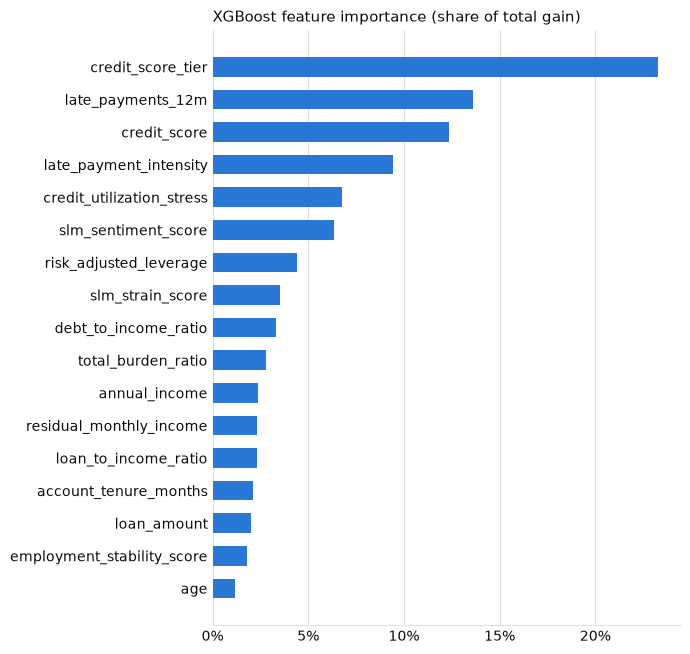

In [7]:
importance = (
    pd.Series(final_model.get_booster().get_score(importance_type='gain'), name='Gain')
    .reindex(xgb_cols, fill_value=0.0)
    .pipe(lambda gain: gain / gain.sum())
    .sort_values(ascending=False)
    .rename_axis('Feature')
)
importance.to_frame().to_csv(RESULTS_DIR / 'xgboost_feature_importance.csv')

INK, MUTED, GRID, BAR = '#0b0b0b', '#898781', '#e1e0d9', '#2a78d6'
plot_data = importance[importance > 0].sort_values()
fig, ax = plt.subplots(figsize=(7, 0.32 * len(plot_data) + 1.2))
ax.barh(plot_data.index, plot_data.values, color=BAR, height=0.6)
ax.set_title('XGBoost feature importance (share of total gain)', loc='left', color=INK, fontsize=11)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f'{value:.0%}'))
ax.grid(axis='x', color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(colors=MUTED, labelcolor=INK, length=0)
for side in ('top', 'right', 'left'):
    ax.spines[side].set_visible(False)
ax.spines['bottom'].set_color(GRID)
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'xgboost_feature_importance.png', dpi=200)
plt.show()

## 6. Key findings

- **The simplest trees work best.** Cross-validation chose single-split trees (depth 1) with a slow learning rate (0.01 × 600 trees); deeper trees did not score higher. Default risk in this dataset behaves mostly additively, leaving few interactions for boosting to exploit, so the tuned XGBoost (test ROC AUC 0.794) does not beat the logistic regression in 04b (0.81). Tuning still matters: default parameters overfit (ROC AUC 0.755, log loss 0.64 vs 0.42 tuned).
- **The Qwen text scores help slightly.** With the same tuned settings, adding the two Qwen scores raises test ROC AUC from 0.787 to 0.794 and PR AUC from 0.497 to 0.521. The gain is small on a 240-row test set, so treat it as indicative.
- **The threshold decides how many defaulters are caught.** At 0.50 the model flags 12 of 50 defaulters (recall 24%). The training-selected threshold of 0.36 flags 19 (recall 38%, F1 0.45, macro F1 0.66) at the cost of 9 more false alarms.
- **Credit history drives the predictions.** Credit score (tier and raw score, 36% of total gain) and late payments (count and intensity, 23%) dominate. Qwen sentiment ranks sixth (6%). Income, loan size, tenure, employment and age each contribute under 3%.